<a href="https://colab.research.google.com/github/mmd0278/Merveille_INFO4670_Fall2026/blob/main/INFO4670_Assignment5_SMS_Spam_Completed_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [79]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

### Q1a. Which error is more costly?

> I consider a false positive (blocking a legitimate text) the more costly error. A blocked message could contain a doctor's appointment reminder, a job interview invitation, or an emergency notification. A false negative means spam reaches the user, exposing them to unwanted advertisements or phishing attempts. Both matter, but wrongly blocking real communication could cause immediate harm.

### Q1b. Primary metric

> I would prioritize **precision for the spam class** because high precision means that most messages we label spam really are spam, reducing incorrect blocking of legitimate texts. I would also monitor recall to make sure the filter still catches a useful number of spam messages. An F1 score provides an overall balance, but precision is my first priority for this use case.

### Q1c. Dummy model

> The baseline would predict ham for every message and score approximately **86.6% accuracy** (4,825 out of 5,572), since most texts are legitimate. That is misleading because it catches none of the 747 spam messages, so spam recall and F1 score are both zero.


---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [80]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


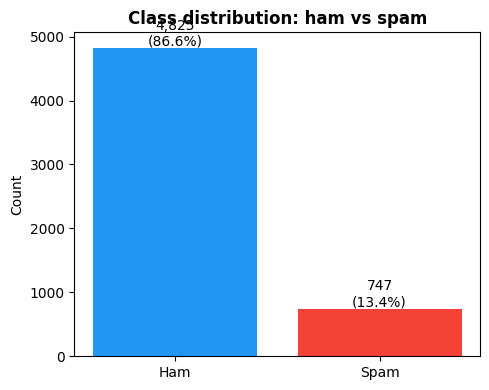

In [95]:
# Write your code here
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [82]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


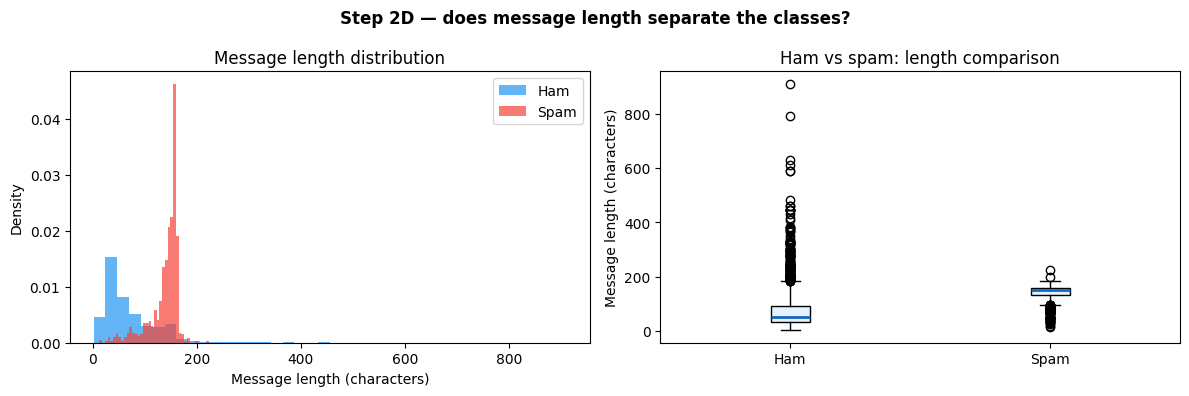

In [83]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [84]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [85]:
# Two new binary indicators: a web link and a reply/text call-to-action.
def build_features_v2(df):
    d = build_features(df)   # keep the provided starter features
    msg = d['message'].str.lower()

    # New feature 1: URL patterns often appear in scam links.
    d['has_url'] = msg.str.contains(r'https?://|www\.|\b[a-z0-9-]+\.(?:com|net|org|co\.uk)\b', regex=True).astype(int)

    # New feature 2: instructions to respond to a short code or reply.
    d['has_reply_cta'] = msg.str.contains(r'\b(?:reply|txt|text)\b', regex=True).astype(int)
    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
feature_gaps = {}
for feat in feature_cols:
    sp = df.loc[df['spam']==1, feat].mean()
    ha = df.loc[df['spam']==0, feat].mean()
    feature_gaps[feat] = sp - ha
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')
print('Largest absolute gap:', max(feature_gaps, key=lambda f: abs(feature_gaps[f])))


All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_url                18.5%    0.3%  +18.2%
has_reply_cta          40.7%    2.5%  +38.2%
Largest absolute gap: is_long


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


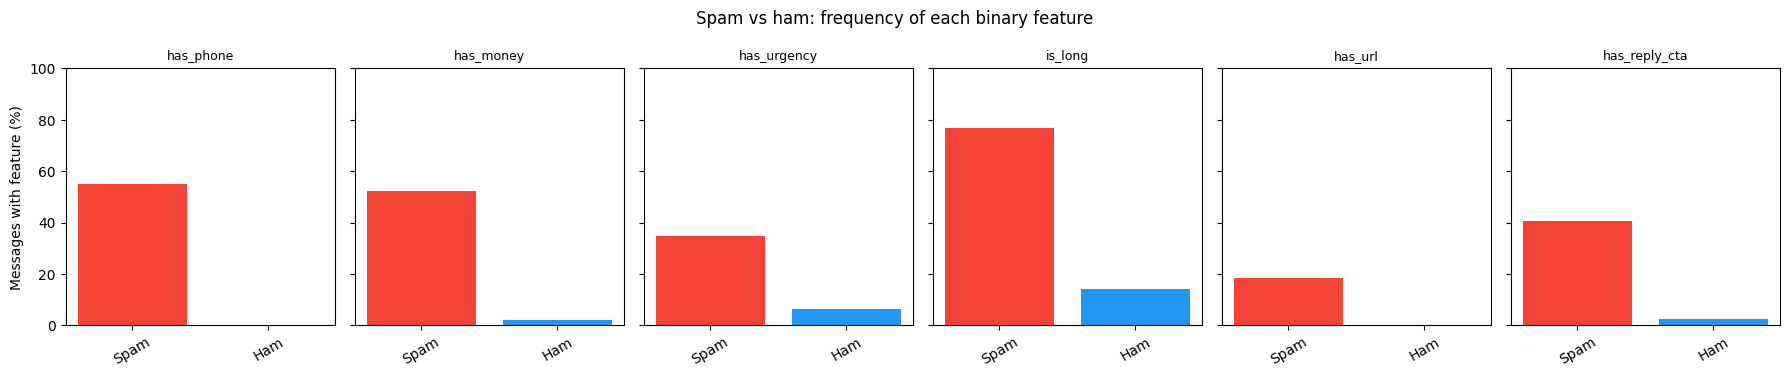

In [86]:
# One small chart per feature, comparing how often each appears in both classes.
n_features = len(feature_cols)
fig, axes = plt.subplots(1, n_features, figsize=(3*n_features, 3.8), sharey=True)
for ax, feat in zip(np.atleast_1d(axes), feature_cols):
    spam_pct = df.loc[df['spam']==1, feat].mean()*100
    ham_pct = df.loc[df['spam']==0, feat].mean()*100
    ax.bar(['Spam','Ham'], [spam_pct, ham_pct], color=['#F44336','#2196F3'])
    ax.set_title(feat, fontsize=9)
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', labelrotation=30)
axes[0].set_ylabel('Messages with feature (%)')
plt.suptitle('Spam vs ham: frequency of each binary feature', fontsize=12)
plt.tight_layout()
plt.show()


### Q3 — Feature Engineering

**Q3a. Two new features**

> **Feature 1, `has_url`:** This detects links, including `http`, `www`, and common domain endings. Suspicious messages may send people to a website to claim a reward or enter account information, so I expected links to be more common in spam.

> **Feature 2, `has_reply_cta`:** This detects words like "reply," "txt," and "text." Some spam tries to make people respond to a number or join a paid texting service, so those calls to action may help distinguish spam from ordinary conversations.

**Q3b. Biggest feature gap and Information Gain**

> The Step 3B output prints the spam-minus-ham rate for every feature and identifies the feature with the largest absolute gap. A big difference suggests that a feature separates spam and legitimate messages well. A Decision Tree may choose a feature like this near its root when the split yields high **information gain**, reducing uncertainty about the message class. However, the largest raw gap does not automatically guarantee the highest information gain; the algorithm checks the actual class distributions after a split.

**Q3c. A spam message the features could miss**

> A phishing SMS might say, "Your account needs verification; visit the customer portal," without a URL, phone number, reward word, urgency keyword, or the words "reply/txt/text." If it also contains fewer than 130 characters, all six binary flags could be zero. That means our handcrafted features might fail to detect the spam message even though it is dangerous.


---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [87]:
X = df[feature_cols].values
y = df['spam'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f'Train set: {len(y_train):,} messages; spam rate = {y_train.mean():.2%}')
print(f'Test set:  {len(y_test):,} messages; spam rate = {y_test.mean():.2%}')


Train set: 4,179 messages; spam rate = 13.40%
Test set:  1,393 messages; spam rate = 13.42%


### Q4 — Data Split

**Q4a. Why `stratify=y`?**

> Stratification keeps roughly the same spam percentage in the training and test sets. Because only about 13% of messages are spam, an unstratified random split might place too few spam examples in one partition, leading to unstable training or misleading evaluation.

**Q4b. When is cross-validation better?**

> I would prefer k-fold cross-validation when the dataset is small or when I want to compare two models more reliably. Each fold gets a turn as validation data, so the model comparison is less dependent on a single lucky or unlucky train/test split.


---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Number of Decision Tree leaves: 14

Decision Tree rules:
|--- is_long <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply_cta <= 0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply_cta >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_urgency <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_urgency >  0.50
|   |   |   |--- class: 1
|--- is_long >  0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply_cta <= 0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply_cta >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |  

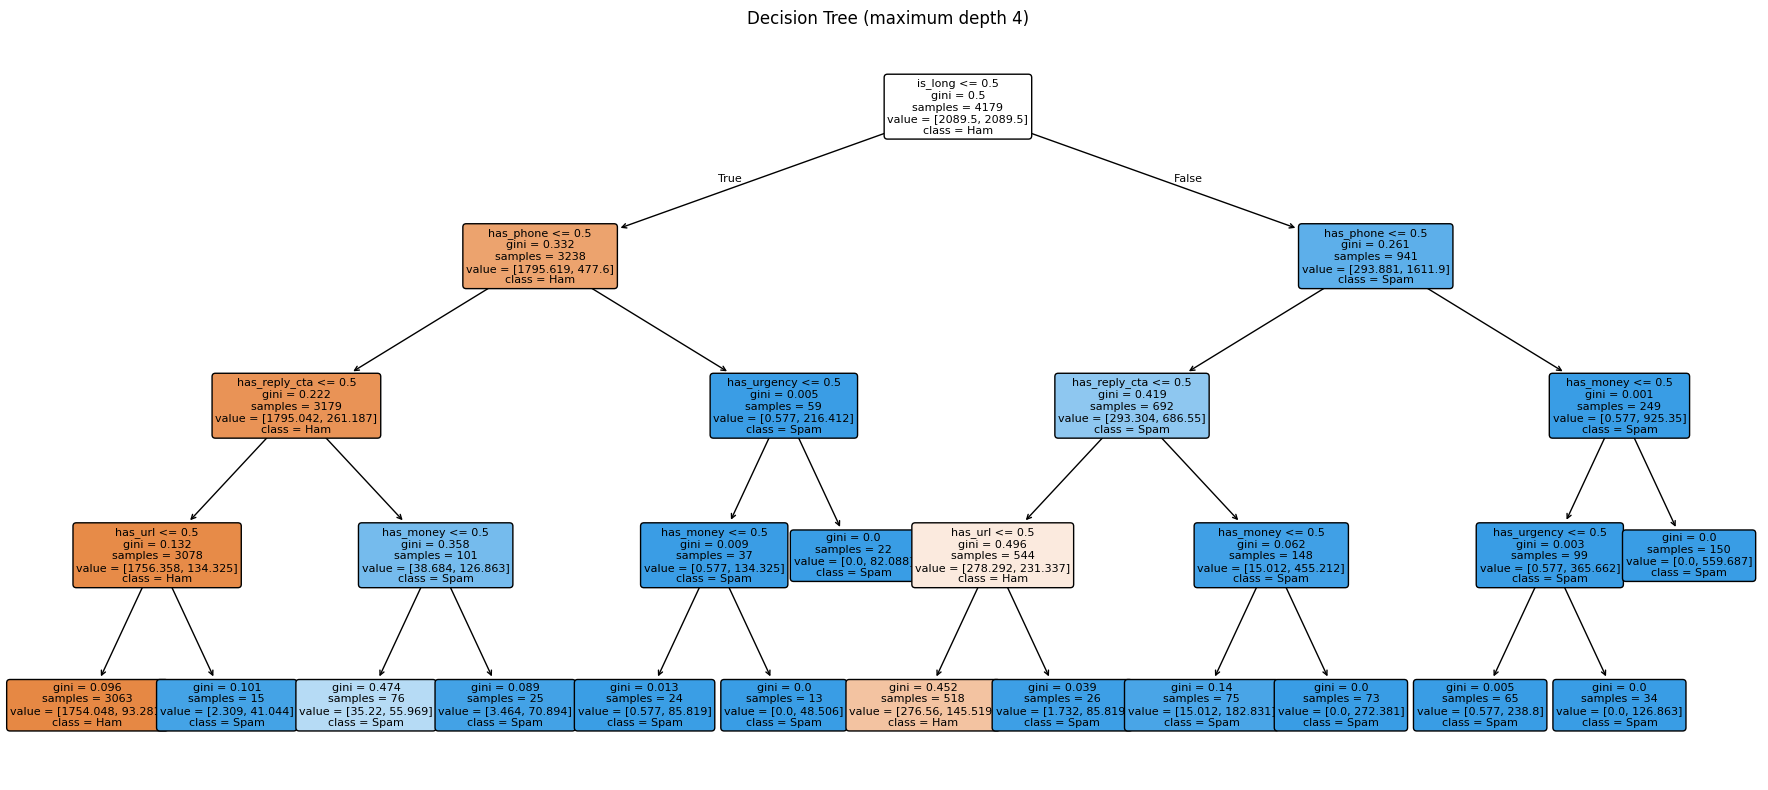

In [88]:
dt = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
dt.fit(X_train, y_train)
print('Number of Decision Tree leaves:', dt.get_n_leaves())
print('\nDecision Tree rules:')
print(export_text(dt, feature_names=feature_cols))
plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=feature_cols, class_names=['Ham','Spam'],
          filled=True, rounded=True, fontsize=8)
plt.title('Decision Tree (maximum depth 4)')
plt.tight_layout()
plt.show()


### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


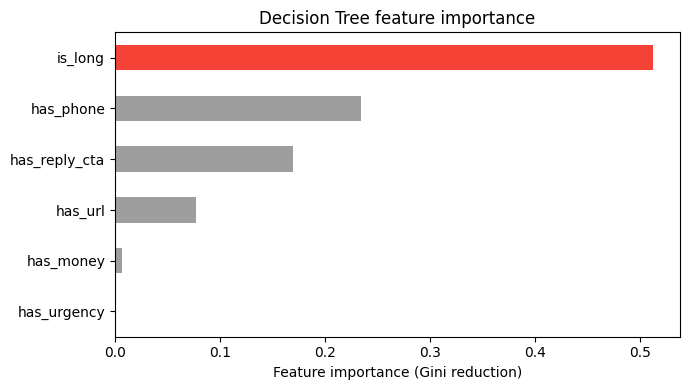

Highest importance: is_long (0.513)


In [89]:
importance = pd.Series(dt.feature_importances_, index=feature_cols).sort_values()
colors = ['#F44336' if name == importance.idxmax() else '#9E9E9E'
          for name in importance.index]
importance.plot(kind='barh', color=colors, figsize=(7, 4))
plt.xlabel('Feature importance (Gini reduction)')
plt.title('Decision Tree feature importance')
plt.tight_layout()
plt.show()
print('Highest importance:', importance.idxmax(), f'({importance.max():.3f})')


### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


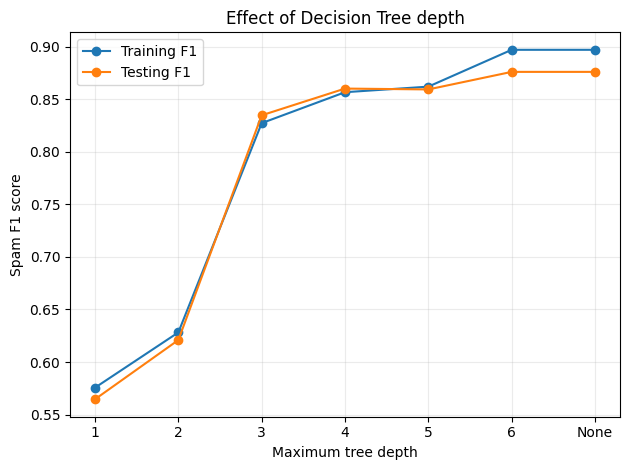

Depth  Train F1  Test F1    Gap
    1     0.576    0.565  0.011
    2     0.628    0.621  0.007
    3     0.827    0.835 -0.007
    4     0.857    0.860 -0.003
    5     0.862    0.859  0.003
    6     0.897    0.876  0.021
 None     0.897    0.876  0.021


In [90]:
depths = [1, 2, 3, 4, 5, 6, None]
train_f1, test_f1 = [], []
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42,
                                   class_weight='balanced')
    model.fit(X_train, y_train)
    train_f1.append(f1_score(y_train, model.predict(X_train), zero_division=0))
    test_f1.append(f1_score(y_test, model.predict(X_test), zero_division=0))

labels = [str(d) if d is not None else 'None' for d in depths]
plt.plot(labels, train_f1, marker='o', label='Training F1')
plt.plot(labels, test_f1, marker='o', label='Testing F1')
plt.xlabel('Maximum tree depth')
plt.ylabel('Spam F1 score')
plt.title('Effect of Decision Tree depth')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(pd.DataFrame({'Depth': labels, 'Train F1':train_f1, 'Test F1':test_f1,
                    'Gap':np.array(train_f1)-np.array(test_f1)}).round(3).to_string(index=False))


### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [91]:
nb_model = BernoulliNB()
nb_model.fit(X_train, y_train)
print('Bernoulli Naive Bayes trained on', len(y_train), 'messages.')


Bernoulli Naive Bayes trained on 4179 messages.


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


Decision Tree: TP=166, FN=21, FP=33, TN=1173
Naive Bayes: TP=163, FN=24, FP=23, TN=1183


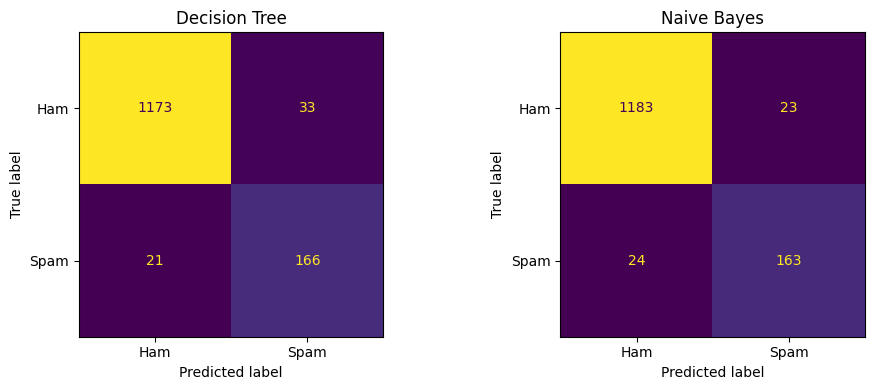

In [92]:
y_pred_dt = dt.predict(X_test)
y_pred_nb = nb_model.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, name in zip(axes, [y_pred_dt,y_pred_nb], ['Decision Tree','Naive Bayes']):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0,1],
             display_labels=['Ham','Spam'], ax=ax, colorbar=False)
    ax.set_title(name)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
    print(f'{name}: TP={tp}, FN={fn}, FP={fp}, TN={tn}')
plt.tight_layout()
plt.show()


### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree     0.961      0.834   0.888     0.860
  Naive Bayes     0.966      0.876   0.872     0.874


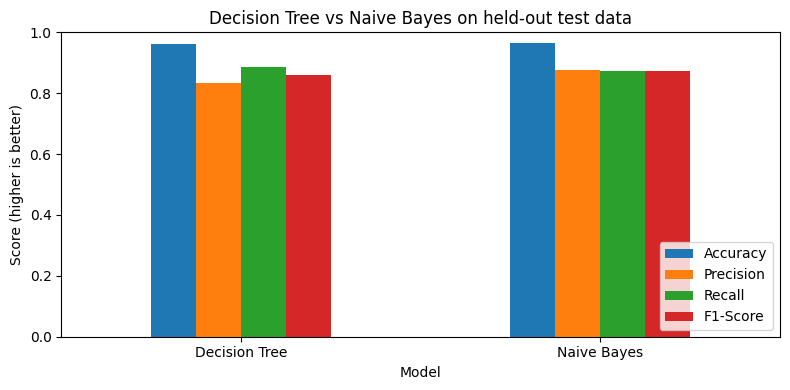

In [93]:
metrics_df = pd.DataFrame([
    {'Model':'Decision Tree','Accuracy':accuracy_score(y_test,y_pred_dt),
     'Precision':precision_score(y_test,y_pred_dt,zero_division=0),
     'Recall':recall_score(y_test,y_pred_dt,zero_division=0),
     'F1-Score':f1_score(y_test,y_pred_dt,zero_division=0)},
    {'Model':'Naive Bayes','Accuracy':accuracy_score(y_test,y_pred_nb),
     'Precision':precision_score(y_test,y_pred_nb,zero_division=0),
     'Recall':recall_score(y_test,y_pred_nb,zero_division=0),
     'F1-Score':f1_score(y_test,y_pred_nb,zero_division=0)},
])
print(metrics_df.round(3).to_string(index=False))
metrics_df.set_index('Model')[['Accuracy','Precision','Recall','F1-Score']].plot(
    kind='bar', figsize=(8,4), rot=0)
plt.ylabel('Score (higher is better)')
plt.ylim(0,1)
plt.title('Decision Tree vs Naive Bayes on held-out test data')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [96]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_dt = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=42,
                         class_weight='balanced'), X_train, y_train, cv=cv, scoring='f1')
cv_nb = cross_val_score(BernoulliNB(), X_train, y_train, cv=cv, scoring='f1')
print('Decision Tree CV F1:', np.round(cv_dt,3), 'mean =', round(cv_dt.mean(),3))
print('Naive Bayes CV F1: ', np.round(cv_nb,3), 'mean =', round(cv_nb.mean(),3))

# Automatically prepare numerical answers from the ACTUAL evaluated dataset.
from IPython.display import display, Markdown
counts = {}
for name, pred in [('Decision Tree',y_pred_dt),('Naive Bayes',y_pred_nb)]:
    tn, fp, fn, tp = confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    counts[name] = dict(tp=int(tp),fp=int(fp),fn=int(fn),tn=int(tn))
ranked = metrics_df.sort_values('Precision',ascending=False)
winner = str(ranked.iloc[0]['Model'])
other = str(ranked.iloc[1]['Model'])
precision_diff = float(ranked.iloc[0]['Precision']-ranked.iloc[1]['Precision'])
cvmeans = {'Decision Tree':cv_dt.mean(),'Naive Bayes':cv_nb.mean()}
cvwinner = max(cvmeans, key=cvmeans.get)
# Q6: precision is our chosen primary metric from Q1b.
response = f"""### Q6a. Confusion matrix results
- **Decision Tree:** TP = {counts['Decision Tree']['tp']}, FN = {counts['Decision Tree']['fn']}, FP = {counts['Decision Tree']['fp']} (TN = {counts['Decision Tree']['tn']}).
- **Naive Bayes:** TP = {counts['Naive Bayes']['tp']}, FN = {counts['Naive Bayes']['fn']}, FP = {counts['Naive Bayes']['fp']} (TN = {counts['Naive Bayes']['tn']}).

### Q6b. Primary metric: Precision
**{winner}** has higher spam precision by **{precision_diff:.1%}** than {other}. Cross-validation evaluates **F1**, not precision, so it cannot directly confirm the precision ranking. Its mean F1 favored **{cvwinner}**, with Decision Tree = {cv_dt.mean():.3f} and Naive Bayes = {cv_nb.mean():.3f}; this is useful additional evidence, but it measures a different tradeoff.

### Q6c. Recommendation memo
I recommend the **{winner}** model for the mobile carrier's initial spam filter because it achieved **{float(ranked.iloc[0]['Precision']):.1%} spam precision** on the held-out test set. This matters because filtering out a legitimate SMS could mean missing an important message. One weakness is that even this model missed **{counts[winner]['fn']} spam texts**, so some unwanted messages will still reach customers. I would improve the system by collecting more recent SMS examples and adding stronger text features, then evaluate it on new data before deployment. I would also monitor recall alongside precision as the system is updated.

### Q6d. Modern spam and features that may fail
Our **`has_money`** feature could miss modern phishing messages that ask users to verify their accounts but never mention free prizes, cash or winning. Our **`has_reply_cta`** feature could miss polished scam messages that direct the recipient to a legitimate-looking landing page without using the words "reply," "txt," or "text." These simple word indicators cannot understand the underlying intent of the message.
"""
display(Markdown(response))


Decision Tree CV F1: [0.851 0.846 0.876 0.847 0.848] mean = 0.853
Naive Bayes CV F1:  [0.877 0.874 0.919 0.88  0.889] mean = 0.888


### Q6a. Confusion matrix results
- **Decision Tree:** TP = 166, FN = 21, FP = 33 (TN = 1173).
- **Naive Bayes:** TP = 163, FN = 24, FP = 23 (TN = 1183).

### Q6b. Primary metric: Precision
**Naive Bayes** has higher spam precision by **4.2%** than Decision Tree. Cross-validation evaluates **F1**, not precision, so it cannot directly confirm the precision ranking. Its mean F1 favored **Naive Bayes**, with Decision Tree = 0.853 and Naive Bayes = 0.888; this is useful additional evidence, but it measures a different tradeoff.

### Q6c. Recommendation memo
I recommend the **Naive Bayes** model for the mobile carrier's initial spam filter because it achieved **87.6% spam precision** on the held-out test set. This matters because filtering out a legitimate SMS could mean missing an important message. One weakness is that even this model missed **24 spam texts**, so some unwanted messages will still reach customers. I would improve the system by collecting more recent SMS examples and adding stronger text features, then evaluate it on new data before deployment. I would also monitor recall alongside precision as the system is updated.

### Q6d. Modern spam and features that may fail
Our **`has_money`** feature could miss modern phishing messages that ask users to verify their accounts but never mention free prizes, cash or winning. Our **`has_reply_cta`** feature could miss polished scam messages that direct the recipient to a legitimate-looking landing page without using the words "reply," "txt," or "text." These simple word indicators cannot understand the underlying intent of the message.


### Q6 — Evaluation & Analysis

**Q6a–Q6d. Written responses (based on actual test predictions):**

> The cell immediately above generates the completed Q6a through Q6d responses using the actual calculated confusion matrices, precision scores, and cross-validation results. **Run all cells in order** to display the numerical answers. Never substitute untested example numbers.
